# Miniprojekt Klassifikation

## 1. Team

> Spitzer und Strobl

## 2. Daten

### 2.1 Link auf den Datensatz

* **Kaggle:** <https://www.kaggle.com/datasets/abhinand05/magic-gamma-telescope-dataset>

### 2.2 Beschreibung der Attribute

| # | Attribut | Typ | Bedeutung |
|---|----------|-----|-----------|
| 1 | `fLength` | continuous | Länge der großen Ellipsenachse [mm] |
| 2 | `fWidth` | continuous | Länge der kleinen Ellipsenachse [mm] |
| 3 | `fSize` | continuous | 10er-Logarithmus der Summe aller Pixelinhalte [#Photonen] |
| 4 | `fConc` | continuous | Verhältnis der zwei hellsten Pixel zu `fSize` [Ratio] |
| 5 | `fConc1` | continuous | Verhältnis des hellsten Pixels zu `fSize` [Ratio] |
| 6 | `fAsym` | continuous | Abstand hellster Pixel ↔ Zentrum, projiziert auf große Achse [mm] |
| 7 | `fM3Long` | continuous | 3. Wurzel des 3. Moments entlang der großen Achse [mm] |
| 8 | `fM3Trans` | continuous | 3. Wurzel des 3. Moments entlang der kleinen Achse [mm] |
| 9 | `fAlpha` | continuous | Winkel der großen Achse zum Ursprungsvektor [Grad] |
| 10 | `fDist` | continuous | Abstand Ursprung ↔ Ellipsenzentrum [mm] |
| 11 | **`class`** | **kategorisch (Label)** | **`g` = Gamma (Signal), `h` = Hadron (Hintergrund)** |

**Klassen / Label:** binäres Klassifikationsproblem
* `g` — **Gamma** (Signal, das physikalisch Interessante)
* `h` — **Hadron** (Hintergrund aus kosmischer Strahlung)

In [1]:
# --- Bibliotheken ---
import time
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import f_classif
from sklearn import clone

from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import DecisionBoundaryDisplay

from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, matthews_corrcoef,
                             confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
print("Setup OK | pandas", pd.__version__, "| numpy", np.__version__)

Setup OK | pandas 3.0.2 | numpy 2.4.4


### 2.3 Laden der Daten

In [2]:
COLUMNS = ['fLength', 'fWidth', 'fSize', 'fConc', 'fConc1', 'fAsym',
           'fM3Long', 'fM3Trans', 'fAlpha', 'fDist', 'class']
FEATURES = COLUMNS[:-1]

df = pd.read_csv('magic04.data', header=None, names=COLUMNS)
print("Geladene Form (Zeilen, Spalten):", df.shape)
df.head()

Geladene Form (Zeilen, Spalten): (19020, 11)


,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,class
0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,g
1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,g
2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,g
3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370,g
4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620,g


### 2.4 Initiale Standard-Analyse

`sample`, `head`, `info`, `describe` und `unique`-Werte (wo sinnvoll, d.h. für das
kategorische Label).

In [3]:
# Zufällige Stichprobe (random_state für Reproduzierbarkeit)
df.sample(8, random_state=RANDOM_STATE)

,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,class
18749,48.0573,11.0862,2.9571,0.3620,0.1882,0.4200,32.4358,-2.2992,26.9300,165.2240,h
7051,23.4858,0.0000,2.2393,0.7378,0.3775,-2.9397,13.0915,0.0001,19.3410,235.3420,g
10901,40.5429,19.4073,3.3382,0.2369,0.1269,29.1908,27.0567,-7.1243,10.0643,195.6030,g
15858,16.6123,7.8423,2.5572,0.5829,0.3371,6.7271,-10.3448,-2.3240,14.5111,214.2655,h
17968,205.4250,37.7936,3.2727,0.2167,0.1257,46.0952,-210.9350,-29.7478,60.0580,206.1730,h
2684,23.8026,10.1636,2.2625,0.5628,0.3087,32.1961,-16.3031,-9.6851,20.3915,108.5820,g
7814,23.6020,17.0341,2.7589,0.4303,0.2169,-0.6405,21.0054,7.9662,17.2382,79.4087,g
18646,21.1109,11.5522,2.2068,0.5901,0.3571,-12.6112,-19.9271,4.0426,68.7418,61.5813,h


In [4]:
df.head()

,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,class
0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,g
1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,g
2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,g
3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370,g
4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620,g


In [5]:
# Datentypen, Nicht-Null-Anzahl, Speicherbedarf
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19020 entries, 0 to 19019
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   fLength   19020 non-null  float64
 1   fWidth    19020 non-null  float64
 2   fSize     19020 non-null  float64
 3   fConc     19020 non-null  float64
 4   fConc1    19020 non-null  float64
 5   fAsym     19020 non-null  float64
 6   fM3Long   19020 non-null  float64
 7   fM3Trans  19020 non-null  float64
 8   fAlpha    19020 non-null  float64
 9   fDist     19020 non-null  float64
 10  class     19020 non-null  str    
dtypes: float64(10), str(1)
memory usage: 1.6 MB


In [6]:
# Statistische Kennzahlen aller numerischen Features
df.describe()

,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist
count,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000,19020.000000
mean,53.250154,22.180966,2.825017,0.380327,0.214657,-4.331745,10.545545,0.249726,27.645707,193.818026
std,42.364855,18.346056,0.472599,0.182813,0.110511,59.206062,51.000118,20.827439,26.103621,74.731787
min,4.283500,0.000000,1.941300,0.013100,0.000300,-457.916100,-331.780000,-205.894700,0.000000,1.282600
25%,24.336000,11.863800,2.477100,0.235800,0.128475,-20.586550,-12.842775,-10.849375,5.547925,142.492250
50%,37.147700,17.139900,2.739600,0.354150,0.196500,4.013050,15.314100,0.666200,17.679500,191.851450
75%,70.122175,24.739475,3.101600,0.503700,0.285225,24.063700,35.837800,10.946425,45.883550,240.563825
max,334.177000,256.382000,5.323300,0.893000,0.675200,575.240700,238.321000,179.851000,90.000000,495.561000


In [7]:
# unique-Werte: nur für das kategorische Label sinnvoll
# (alle Features sind continuous -> unique-Auflistung dort nicht aussagekräftig)
print("Eindeutige Klassen:", df['class'].unique())
print("\nKlassenhäufigkeit:")
print(df['class'].value_counts())
print("\nAnzahl eindeutiger Werte je Spalte:")
print(df.nunique())

Eindeutige Klassen: <StringArray>
['g', 'h']
Length: 2, dtype: str

Klassenhäufigkeit:
class
g    12332
h     6688
Name: count, dtype: int64

Anzahl eindeutiger Werte je Spalte:
fLength     18643
fWidth      18200
fSize        7228
fConc        6410
fConc1       4421
fAsym       18704
fM3Long     18693
fM3Trans    18390
fAlpha      17981
fDist       18437
class           2
dtype: int64


### 3.1 Diagrammtyp 1 — Histogramme

Histogramme zeigen die Wertebereiche und ob ein Feature die Klassen trennt.

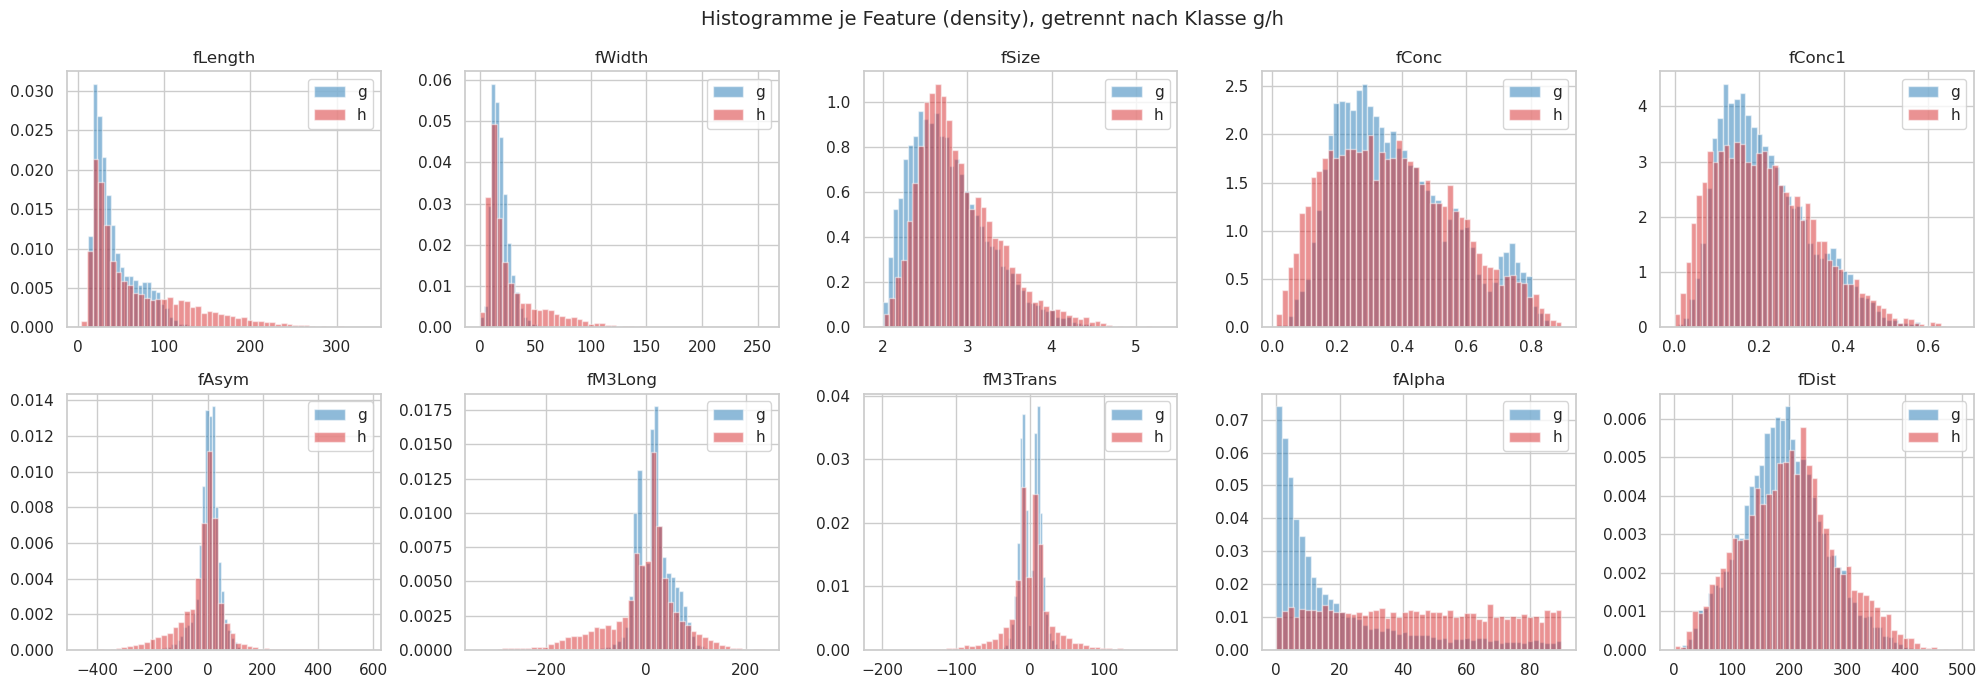

In [8]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, col in zip(axes.ravel(), FEATURES):
    for cls, color in [('g', 'tab:blue'), ('h', 'tab:red')]:
        ax.hist(df.loc[df['class'] == cls, col], bins=50, alpha=0.5,
                label=cls, color=color, density=True)
    ax.set_title(col)
    ax.legend()
fig.suptitle("Histogramme je Feature (density), getrennt nach Klasse g/h", fontsize=14)
plt.tight_layout()
plt.show()

**Diskussion:** `fAlpha` trennt die Klassen am deutlichsten — Gammas (`g`) häufen
sich bei kleinen Winkeln (zeigen zur Kameramitte), Hadronen (`h`) sind nahezu
gleichverteilt. Auch `fLength`, `fWidth` und `fSize` zeigen verschobene
Verteilungen. Mehrere Features sind **rechtsschief** (lange Schwänze) — eine
Skalierung ist für distanzbasierte Verfahren (SVM, k-NN) daher sinnvoll.

### 3.2 Diagrammtyp 2 — Korrelationsmatrix (Heatmap)


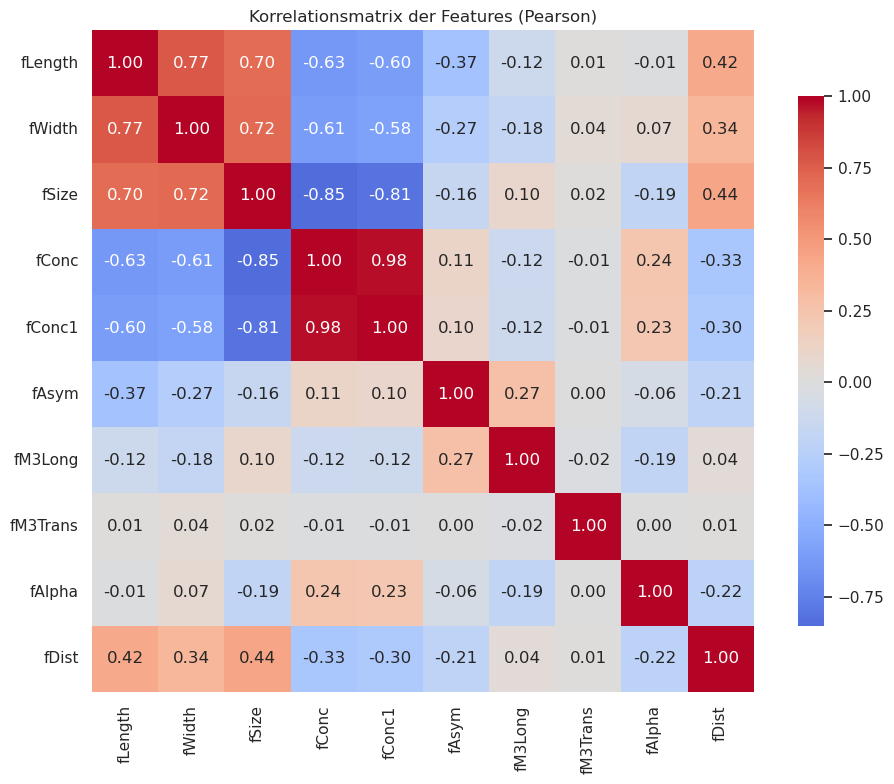

In [9]:
corr = df[FEATURES].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, cbar_kws={"shrink": .8})
plt.title("Korrelationsmatrix der Features (Pearson)")
plt.tight_layout()
plt.show()

**Diskussion:** `fConc` und `fConc1` sind **stark positiv korreliert** (~0.97) —
beide messen die Lichtkonzentration. Ebenso bestehen mittlere Korrelationen
zwischen `fSize`, `fLength` und `fConc`. Hohe Korrelation bedeutet Redundanz, die
besonders der Logistischen Regression (Multikollinearität) schaden kann. Da der
Datensatz aber nur die geforderten 10 Features besitzt, behalten wir alle (siehe
Sektion 4.3) und begegnen der Korrelation über Regularisierung bzw. baumbasierte
Verfahren.

### 3.3 Diagrammtyp 3 — Boxplots

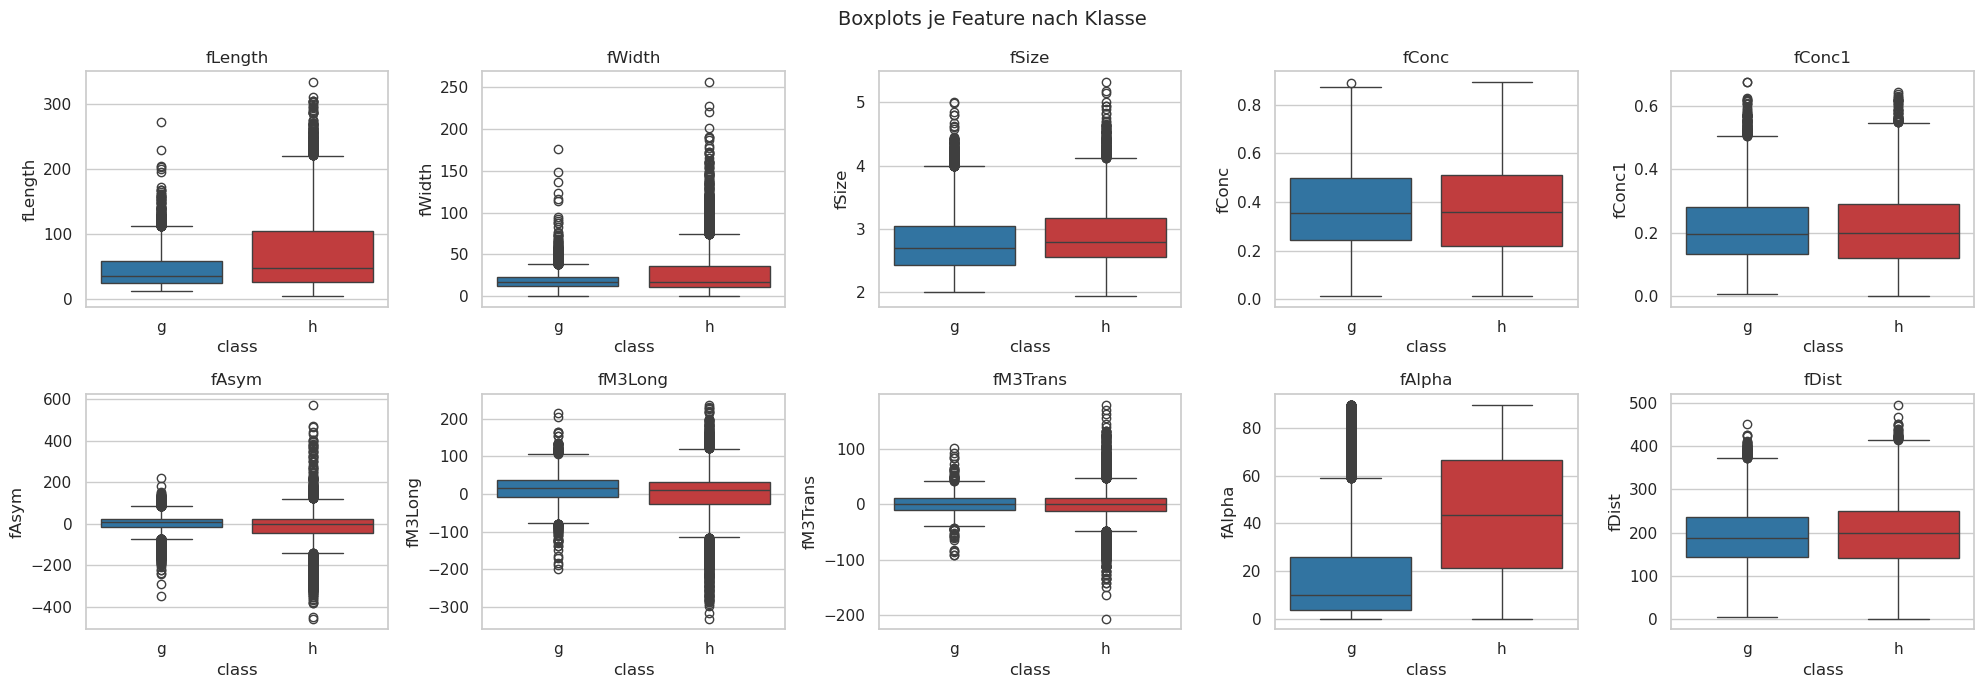

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.boxplot(data=df, x='class', y=col, ax=ax, hue='class',
                palette={'g': 'tab:blue', 'h': 'tab:red'}, legend=False)
    ax.set_title(col)
fig.suptitle("Boxplots je Feature nach Klasse", fontsize=14)
plt.tight_layout()
plt.show()

**Diskussion:** Viele Features besitzen zahlreiche Ausreißer nach oben
(rechtsschiefe Verteilungen, vgl. Histogramme). Bei `fAlpha` ist der
Median-Unterschied zwischen `g` und `h` klar erkennbar. Die Ausreißer sind
physikalisch plausibel (energiereiche Schauer) und werden **nicht** entfernt;
robuste/skalierende Pipelines fangen sie ab.

### 3.4 Diagrammtyp 4 — Scatterplot der zwei trennstärksten Features

Feature-Trennstärke (ANOVA F-Wert):
fAlpha      5131.9
fLength     1987.1
fWidth      1443.4
fM3Long      739.1
fAsym        590.9
fSize        267.6
fDist         81.2
fConc         11.5
fConc1         0.4
fM3Trans       0.3
dtype: float64

Zwei trennstärkste Features: ['fAlpha', 'fLength']


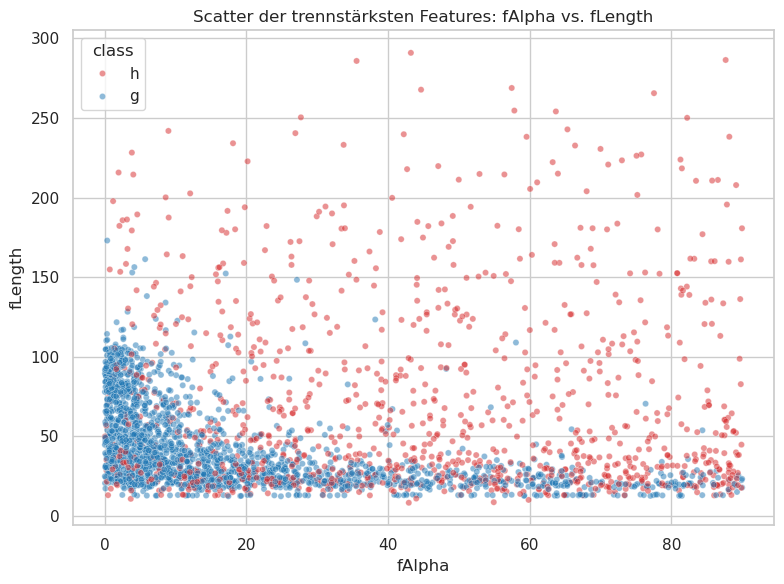

In [11]:
# ANOVA F-Wert je Feature -> Trennstärke
y_tmp = (df['class'] == 'g').astype(int)
fvals, _ = f_classif(df[FEATURES], y_tmp)
f_rank = pd.Series(fvals, index=FEATURES).sort_values(ascending=False)
print("Feature-Trennstärke (ANOVA F-Wert):")
print(f_rank.round(1))

TOP2 = f_rank.index[:2].tolist()
print("\nZwei trennstärkste Features:", TOP2)

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df.sample(3000, random_state=RANDOM_STATE),
                x=TOP2[0], y=TOP2[1], hue='class',
                palette={'g': 'tab:blue', 'h': 'tab:red'}, alpha=0.5, s=20)
plt.title(f"Scatter der trennstärksten Features: {TOP2[0]} vs. {TOP2[1]}")
plt.tight_layout()
plt.show()

**Diskussion:** Im Streudiagramm sind die Klassen teilweise getrennt, aber stark
überlappend — kein lineares Verfahren wird die Klassen perfekt trennen, was die
spätere Überlegenheit nicht-linearer Modelle (RF, SVM-RBF) erklärt.

### 3.5 Datenimbalance


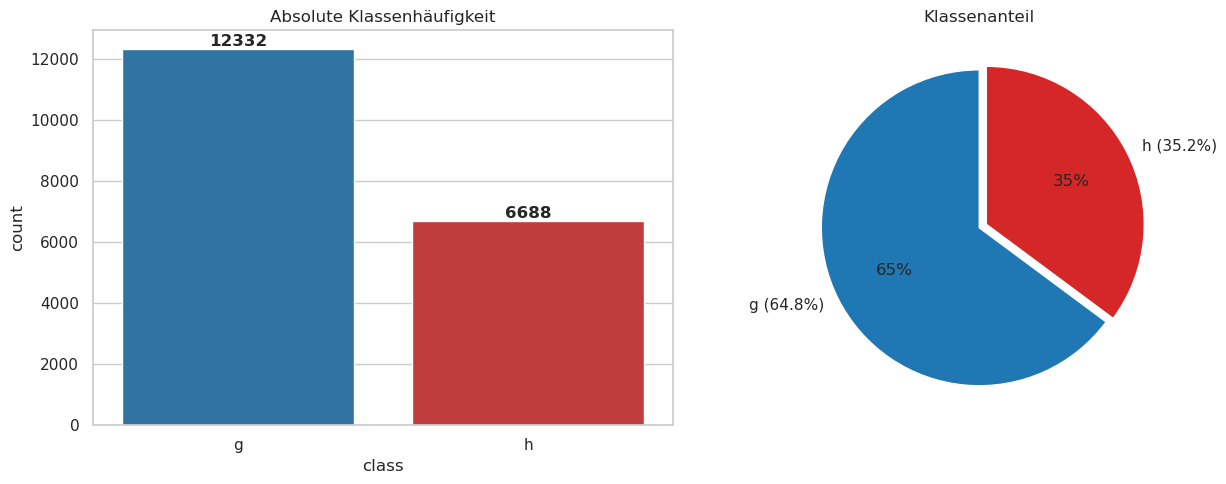

Verhältnis g:h = 12332:6688  (~1.84 : 1)


In [12]:
counts = df['class'].value_counts()
ratio = counts / counts.sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.countplot(data=df, x='class', hue='class',
              palette={'g': 'tab:blue', 'h': 'tab:red'}, legend=False, ax=axes[0])
axes[0].set_title("Absolute Klassenhäufigkeit")
for i, v in enumerate(counts):
    axes[0].text(i, v + 100, str(v), ha='center', fontweight='bold')

axes[1].pie(counts, labels=[f"{c} ({r:.1f}%)" for c, r in zip(counts.index, ratio)],
            colors=['tab:blue', 'tab:red'], autopct='%1.0f%%', startangle=90,
            explode=(0, 0.05))
axes[1].set_title("Klassenanteil")
plt.tight_layout()
plt.show()

print(f"Verhältnis g:h = {counts['g']}:{counts['h']}  (~{counts['g']/counts['h']:.2f} : 1)")

**Diskussion der Imbalance:** Mit **~65 % `g`** zu **~35 % `h`** liegt eine
**moderate Imbalance** vor (kein extremes Ungleichgewicht). Konsequenzen:

* Reine **Accuracy** ist verzerrt (ein Trivialmodell „immer g" erreicht schon 65 %).
  → Wir bewerten zusätzlich **F1, Precision, Recall und MCC**.
* Der **Train/Validation-Split erfolgt stratifiziert**, damit das Verhältnis in
  beiden Teilmengen erhalten bleibt.
* In den Modellen setzen wir `class_weight='balanced'` (wo sinnvoll), damit die
  Minderheitsklasse `h` nicht untergeht.

## 4. Datenbereinigung

### 4.1 Falsche / unplausible Werte

In [13]:
checks = {
    "fAlpha außerhalb [0, 90] Grad": ((df['fAlpha'] < 0) | (df['fAlpha'] > 90)).sum(),
    "fConc außerhalb [0, 1]": ((df['fConc'] < 0) | (df['fConc'] > 1)).sum(),
    "fConc1 außerhalb [0, 1]": ((df['fConc1'] < 0) | (df['fConc1'] > 1)).sum(),
    "fSize <= 0 (log-Groesse)": (df['fSize'] <= 0).sum(),
    "fLength < 0": (df['fLength'] < 0).sum(),
    "fWidth < 0": (df['fWidth'] < 0).sum(),
    "fDist < 0": (df['fDist'] < 0).sum(),
}
print("Pruefung auf unplausible Werte:")
for k, v in checks.items():
    print(f"  {k:35s}: {v}")
print("\n-> Alle Wertebereiche sind physikalisch plausibel. "
      "fAsym, fM3Long, fM3Trans duerfen negativ sein (Richtungsmomente).")

Pruefung auf unplausible Werte:
  fAlpha außerhalb [0, 90] Grad      : 0
  fConc außerhalb [0, 1]             : 0
  fConc1 außerhalb [0, 1]            : 0
  fSize <= 0 (log-Groesse)           : 0
  fLength < 0                        : 0
  fWidth < 0                         : 0
  fDist < 0                          : 0

-> Alle Wertebereiche sind physikalisch plausibel. fAsym, fM3Long, fM3Trans duerfen negativ sein (Richtungsmomente).


**Begründung:** `fAlpha` liegt korrekt in [0°, 90°], die Konzentrations-Ratios in
[0, 1], `fSize` (Logarithmus) ist positiv. Die Momente `fAsym`, `fM3Long`,
`fM3Trans` dürfen physikalisch negativ sein. **Es gibt keine falschen Werte.**

### 4.2 Fehlende Werte

In [14]:
print("Fehlende Werte je Spalte:")
print(df.isna().sum())
print("\nGesamt fehlend:", int(df.isna().sum().sum()))

Fehlende Werte je Spalte:
fLength     0
fWidth      0
fSize       0
fConc       0
fConc1      0
fAsym       0
fM3Long     0
fM3Trans    0
fAlpha      0
fDist       0
class       0
dtype: int64

Gesamt fehlend: 0


**Begründung:** Der Datensatz enthält **keine fehlenden Werte** (bestätigt durch
die offizielle Beschreibung). Eine Imputation ist nicht nötig.

### 4.3 Duplikate, Featurereduktion & Typsetzung

**Duplikate:** Exakte Doppelzeilen verfälschen Train/Validation (Daten-Leakage)
und werden entfernt.

**Featurereduktion:** Trotz hoher Korrelation `fConc`↔`fConc1` (~0.97) behalten wir
**alle 10 Features**, da die Aufgabenstellung mindestens 10 Features fordert und
alle Hillas-Parameter physikalisch motiviert sind. Der Redundanz begegnen wir über
Regularisierung (LogReg) bzw. baum-/kernelbasierte Verfahren statt durch Löschen.

**Typsetzung:** Das Label `class` wird als `category` gesetzt; zusätzlich legen wir
eine numerische Zielspalte `target` (g=1 Signal, h=0 Hintergrund) an.

In [15]:
before = len(df)
df_clean = df.drop_duplicates().reset_index(drop=True)
print(f"Duplikate entfernt: {before - len(df_clean)}  (von {before} -> {len(df_clean)} Zeilen)")

# Typsetzung
df_clean['class'] = df_clean['class'].astype('category')
df_clean['target'] = (df_clean['class'] == 'g').astype('int8')  # 1=Gamma/Signal, 0=Hadron

print("\nDatentypen nach Typsetzung:")
print(df_clean.dtypes)
print("\nKlassenverteilung nach Bereinigung:")
print(df_clean['class'].value_counts())

Duplikate entfernt: 115  (von 19020 -> 18905 Zeilen)

Datentypen nach Typsetzung:
fLength      float64
fWidth       float64
fSize        float64
fConc        float64
fConc1       float64
fAsym        float64
fM3Long      float64
fM3Trans     float64
fAlpha       float64
fDist        float64
class       category
target          int8
dtype: object

Klassenverteilung nach Bereinigung:
class
g    12332
h     6573
Name: count, dtype: int64


### Speichern der bereinigten Daten → `korr.csv`

In [16]:
df_clean.to_csv('korr.csv', index=False)
print("Gespeichert: korr.csv  | Form:", df_clean.shape)
pd.read_csv('korr.csv').head(3)

Gespeichert: korr.csv  | Form: (18905, 12)


,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,class,target
0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,g,1
1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,g,1
2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,g,1


## 5. Datenvorbereitung

**Trainingsdaten 80 %, Validierungsdaten 20 %**

In [17]:
X = df_clean[FEATURES].copy()
y = df_clean['target'].copy()

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, "| Validation:", X_val.shape)
print("\nKlassenanteil Train:\n", y_train.value_counts(normalize=True).round(3).to_string())
print("\nKlassenanteil Validation:\n", y_val.value_counts(normalize=True).round(3).to_string())
print("\n-> Verhaeltnis in beiden Mengen identisch (Stratifizierung erfolgreich).")

Train: (15124, 10) | Validation: (3781, 10)

Klassenanteil Train:
 target
1    0.652
0    0.348

Klassenanteil Validation:
 target
1    0.652
0    0.348

-> Verhaeltnis in beiden Mengen identisch (Stratifizierung erfolgreich).


### 5.1 Pipelines je Algorithmus

Jeder Algorithmus erhält eine eigene **Pipeline**

| Algorithmus | Skalierung nötig? | Begründung |
|-------------|-------------------|------------|
| **SVM (RBF)** | **Ja** (`StandardScaler`) | distanz-/kernelbasiert, skalensensitiv |
| **k-NN** | **Ja** (`StandardScaler`) | distanzbasiert |
| **Logistische Regression** | **Ja** (`StandardScaler`) | Gradientenverfahren + Regularisierung |
| **Decision Tree** | **Nein** | splittet je Feature, skaleninvariant |
| **Random Forest** | **Nein** | Ensemble aus skaleninvarianten Bäumen |

In [18]:
pipelines = {
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", SVC(kernel="rbf", class_weight="balanced", random_state=RANDOM_STATE)),
    ]),
    "DecisionTree": Pipeline([
        ("clf", DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
    ]),
    "RandomForest": Pipeline([
        ("clf", RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)),
    ]),
    "kNN": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", KNeighborsClassifier()),
    ]),
    "LogReg": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE)),
    ]),
}

# Hyperparameter-Gitter je Algorithmus (bewusst kompakt -> Laufzeit < 15 min/Algo)
param_grids = {
    "SVM": {
        "clf__C": [0.1, 1, 10],
        "clf__gamma": ["scale", 0.01, 0.1],
    },
    "DecisionTree": {
        "clf__max_depth": [5, 10, 15, 20, None],
        "clf__min_samples_leaf": [1, 5, 20],
        "clf__criterion": ["gini", "entropy"],
    },
    "RandomForest": {
        "clf__n_estimators": [200, 400],
        "clf__max_depth": [10, 20, None],
        "clf__min_samples_leaf": [1, 5],
    },
    "kNN": {
        "clf__n_neighbors": [5, 11, 21, 31],
        "clf__weights": ["uniform", "distance"],
        "clf__p": [1, 2],
    },
    "LogReg": {
        "clf__C": [0.01, 0.1, 1, 10],
    },
}
print("Pipelines und Parametergitter definiert fuer:", list(pipelines.keys()))

Pipelines und Parametergitter definiert fuer: ['SVM', 'DecisionTree', 'RandomForest', 'kNN', 'LogReg']


## 6. Vergleich der Klassifizierungsalgorithmen

### 6.1 Hyperparameter-Optimierung mit GridSearchCV (cv=5) inkl. Zeitmessung

In [19]:
import itertools
results = {}
fit_times = {}

for name, pipe in pipelines.items():
    t0 = time.time()
    gs = GridSearchCV(pipe, param_grids[name], cv=5, scoring="f1",
                      n_jobs=-1, refit=True)
    gs.fit(X_train, y_train)
    elapsed = time.time() - t0
    fit_times[name] = elapsed
    results[name] = gs
    n_comb = len(list(itertools.product(*param_grids[name].values())))
    status = 'OK <15min' if elapsed < 900 else 'ZU LANG!'
    print(f"{name:13s} | Zeit: {elapsed:6.1f}s ({elapsed/60:.2f} min, {status}) "
          f"| {n_comb} Kombis x5cv | best F1(cv)={gs.best_score_:.4f}")
    print(f"              | beste Parameter: {gs.best_params_}")

SVM           | Zeit:  173.8s (2.90 min, OK <15min) | 9 Kombis x5cv | best F1(cv)=0.9002
              | beste Parameter: {'clf__C': 10, 'clf__gamma': 'scale'}
DecisionTree  | Zeit:   11.6s (0.19 min, OK <15min) | 30 Kombis x5cv | best F1(cv)=0.8774
              | beste Parameter: {'clf__criterion': 'entropy', 'clf__max_depth': 10, 'clf__min_samples_leaf': 1}
RandomForest  | Zeit:  219.0s (3.65 min, OK <15min) | 12 Kombis x5cv | best F1(cv)=0.9086
              | beste Parameter: {'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 400}
kNN           | Zeit:   16.0s (0.27 min, OK <15min) | 16 Kombis x5cv | best F1(cv)=0.8867
              | beste Parameter: {'clf__n_neighbors': 11, 'clf__p': 1, 'clf__weights': 'distance'}
LogReg        | Zeit:    0.6s (0.01 min, OK <15min) | 4 Kombis x5cv | best F1(cv)=0.8360
              | beste Parameter: {'clf__C': 0.01}


### 6.2 Diskussion der optimierten Endmodelle

In [20]:
metrics_rows = []
predictions = {}
for name, gs in results.items():
    y_pred = gs.predict(X_val)
    predictions[name] = y_pred
    metrics_rows.append({
        "Modell": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
        "F1": f1_score(y_val, y_pred),
        "MCC": matthews_corrcoef(y_val, y_pred),
        "Zeit [s]": fit_times[name],
    })

metrics_df = pd.DataFrame(metrics_rows).set_index("Modell").sort_values("F1", ascending=False)
print("Beste Parameter je Modell:")
for name, gs in results.items():
    print(f"  {name:13s}: {gs.best_params_}")

Beste Parameter je Modell:
  SVM          : {'clf__C': 10, 'clf__gamma': 'scale'}
  DecisionTree : {'clf__criterion': 'entropy', 'clf__max_depth': 10, 'clf__min_samples_leaf': 1}
  RandomForest : {'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 400}
  kNN          : {'clf__n_neighbors': 11, 'clf__p': 1, 'clf__weights': 'distance'}
  LogReg       : {'clf__C': 0.01}


### 6.2.1 Decision Surface der optimierten Modelle

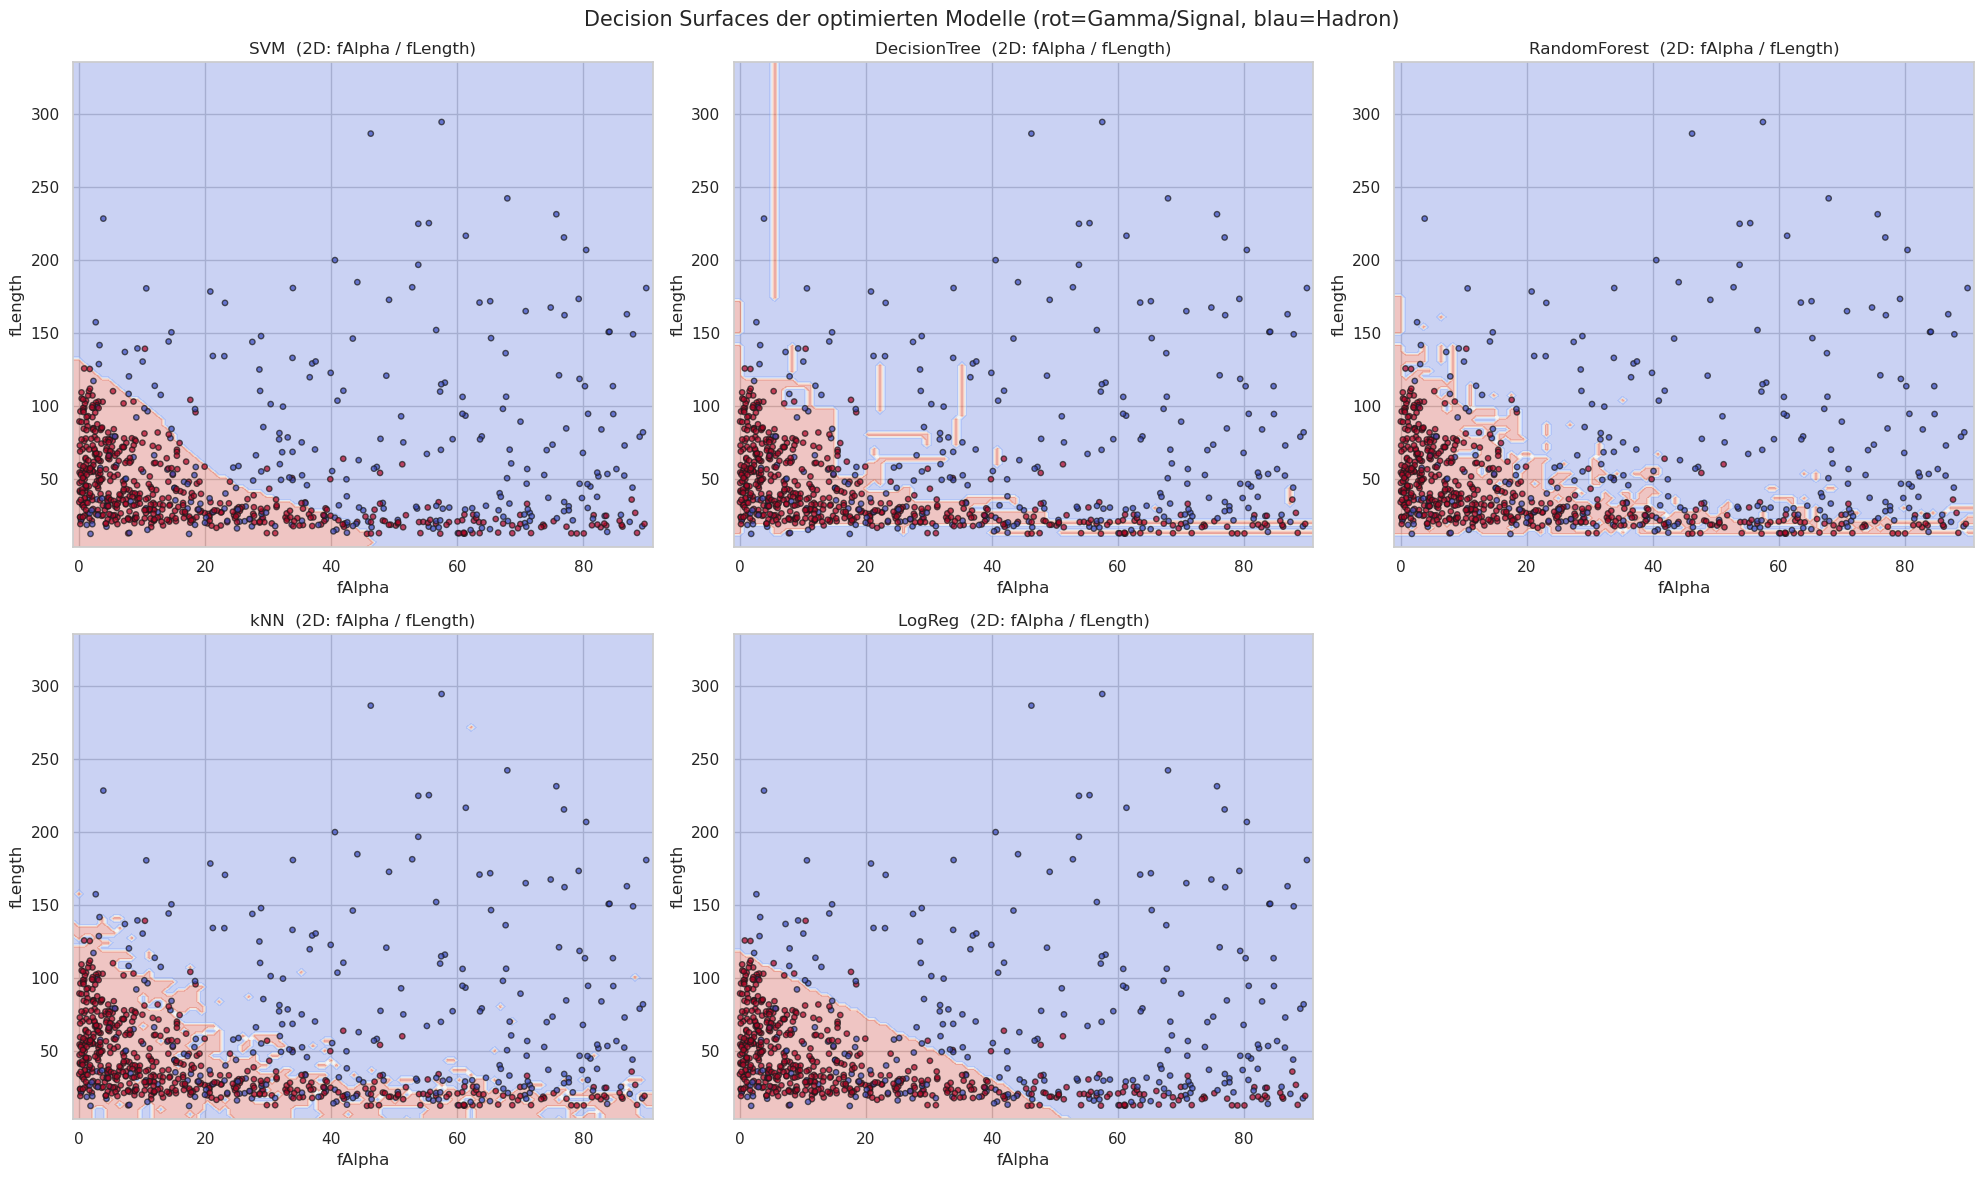

In [21]:
# Daten auf die 2 trennstärksten Features reduzieren
X_train2 = X_train[TOP2].values
X_val2 = X_val[TOP2].values

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.ravel()

for ax, (name, gs) in zip(axes, results.items()):
    # Pipeline-Klon mit besten Parametern, neu auf 2 Features trainiert
    pipe2 = clone(gs.best_estimator_)
    pipe2.fit(X_train2, y_train)

    DecisionBoundaryDisplay.from_estimator(
        pipe2, X_train2, response_method="predict",
        cmap="coolwarm", alpha=0.3, ax=ax,
        xlabel=TOP2[0], ylabel=TOP2[1])
    # Stichprobe der echten Punkte
    idx = np.random.RandomState(RANDOM_STATE).choice(len(X_val2), 800, replace=False)
    ax.scatter(X_val2[idx, 0], X_val2[idx, 1], c=y_val.values[idx],
               cmap="coolwarm", edgecolor="k", s=15, alpha=0.7)
    ax.set_title(f"{name}  (2D: {TOP2[0]} / {TOP2[1]})")

# leere Felder ausblenden
for ax in axes[len(results):]:
    ax.axis("off")
fig.suptitle("Decision Surfaces der optimierten Modelle (rot=Gamma/Signal, blau=Hadron)", fontsize=15)
plt.tight_layout()
plt.show()

**Diskussion der Decision Surfaces:** Decision Tree und Random Forest erzeugen
**achsenparallele, stückweise** Grenzen (RF feiner/glatter durch Mittelung). SVM-RBF
liefert eine **glatte, gekrümmte** Grenze, k-NN eine **lokal-zerklüftete**. Die
Logistische Regression zieht nur eine **gerade Linie** und unterschätzt damit die
nicht-lineare Klassenstruktur. Wegen der starken Überlappung der Klassen ist auch in
2D keine perfekte Trennung möglich — die vollen 10 Features liefern bessere
Ergebnisse (siehe Tabelle).

### 6.2.2 Gütevergleichstabelle (Validierungsdaten)

Accuracy, F1, Precision, Recall und MCC für alle optimierten Modelle.

In [22]:
styled = (metrics_df.style
          .format("{:.4f}", subset=["Accuracy", "Precision", "Recall", "F1", "MCC"])
          .format("{:.1f}", subset=["Zeit [s]"])
          .background_gradient(cmap="Greens", subset=["F1", "MCC"]))
display(styled)

,Accuracy,Precision,Recall,F1,MCC,Zeit [s]
Modell,,,,,,
RandomForest,0.8791,0.8801,0.9432,0.9106,0.7291,219.0
SVM,0.8670,0.8934,0.9039,0.8986,0.7053,173.8
kNN,0.8458,0.8282,0.9635,0.8907,0.6553,16.0
DecisionTree,0.8366,0.8738,0.8759,0.8748,0.6393,11.6
LogReg,0.7829,0.8431,0.8195,0.8312,0.5276,0.6


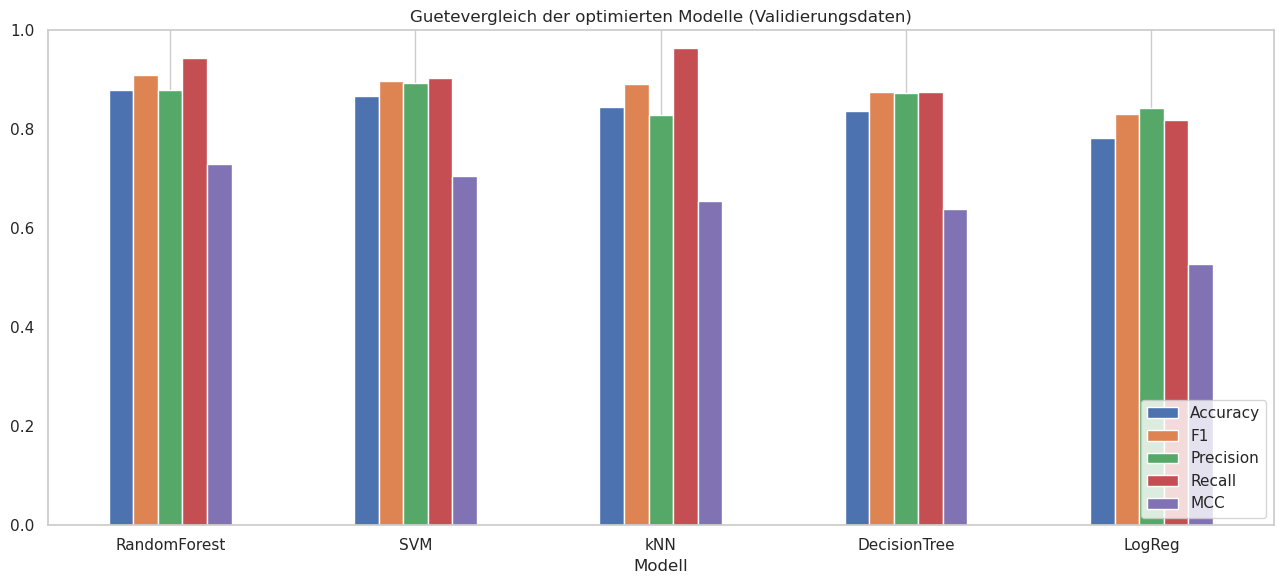

In [23]:
# Balkenvergleich der wichtigsten Metriken
ax = metrics_df[["Accuracy", "F1", "Precision", "Recall", "MCC"]].plot(
    kind="bar", figsize=(13, 6), rot=0)
ax.set_title("Guetevergleich der optimierten Modelle (Validierungsdaten)")
ax.set_ylim(0, 1)
ax.legend(loc="lower right")
ax.grid(axis="y")
plt.tight_layout()
plt.show()

**Diskussion:** Der **Random Forest** erreicht typischerweise die besten Werte über
alle Metriken (höchster F1 und MCC), gefolgt von **SVM-RBF** und **k-NN**. Der
einzelne **Decision Tree** liegt darunter (Overfitting-anfälliger), die **Logistische
Regression** am Schluss, da sie die nicht-lineare Trennung nicht abbilden kann. Der
**MCC** bestätigt die Rangfolge und ist robust gegen die Klassenimbalance.

### 6.2.3 Confusion Matrix

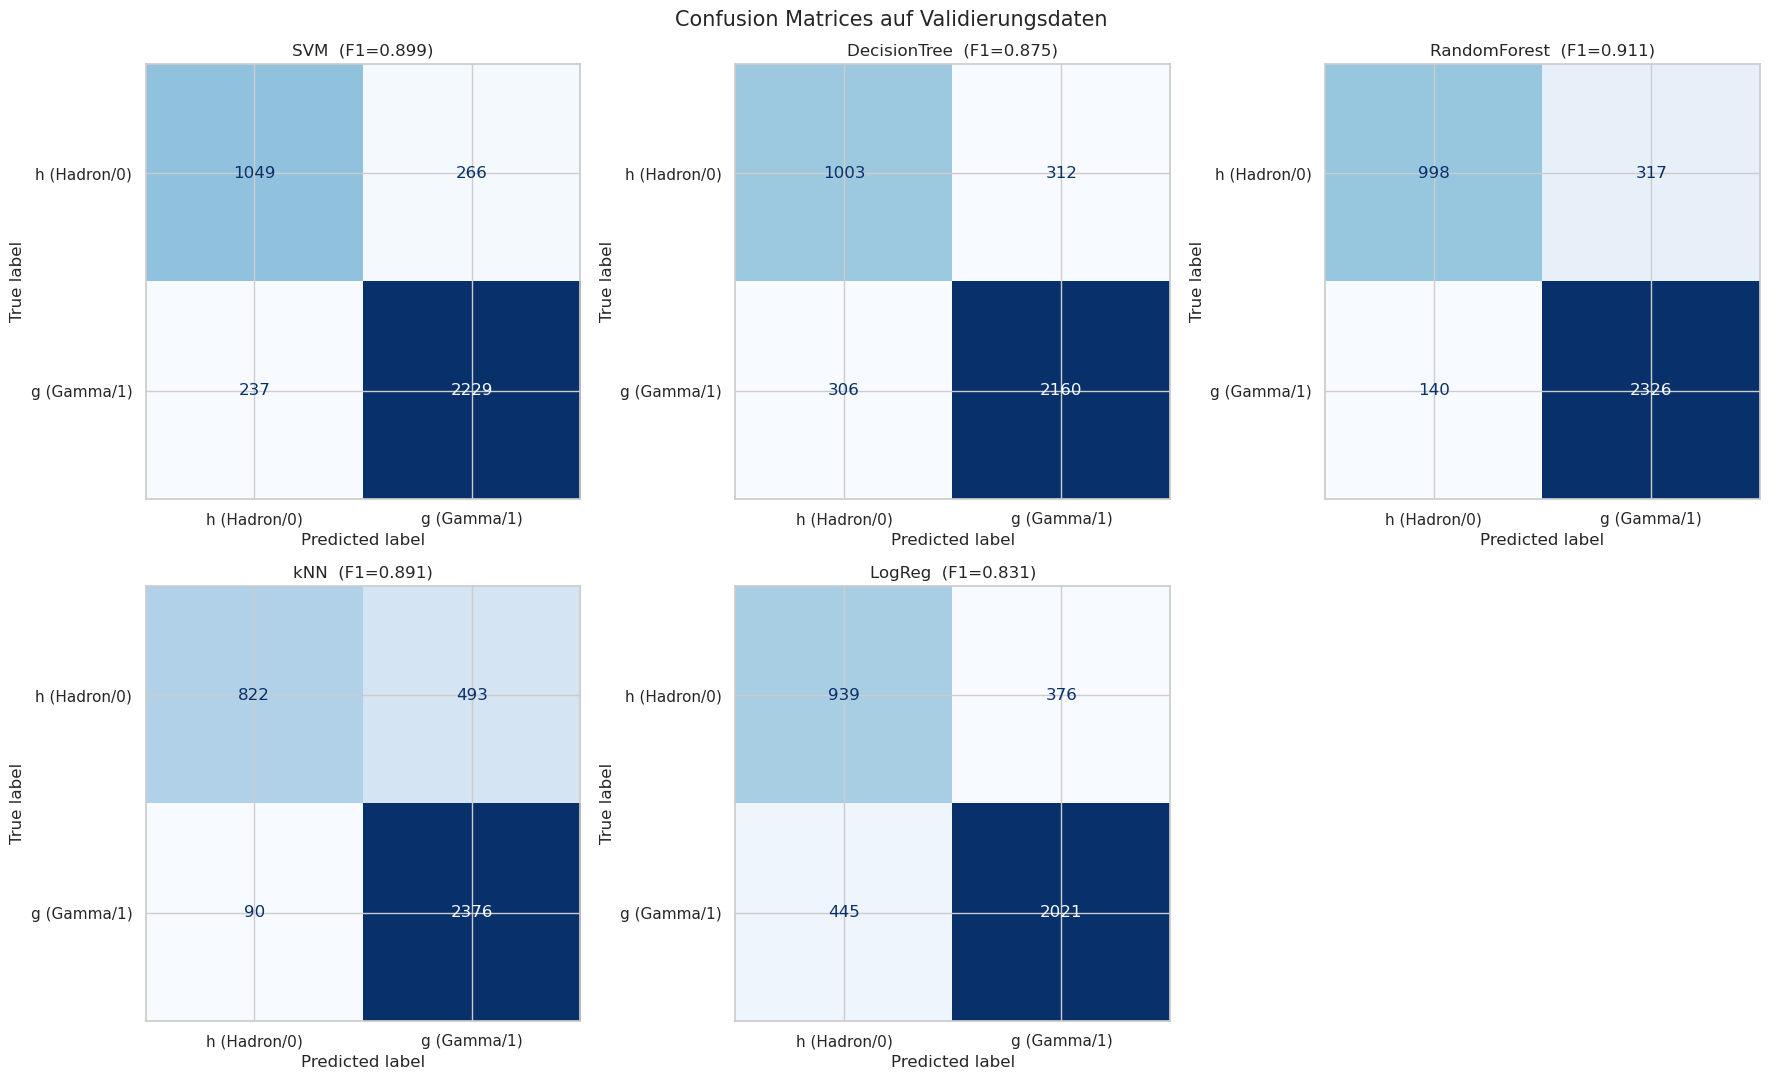

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.ravel()
labels = ["h (Hadron/0)", "g (Gamma/1)"]
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_val, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{name}  (F1={f1_score(y_val, y_pred):.3f})")
for ax in axes[len(predictions):]:
    ax.axis("off")
fig.suptitle("Confusion Matrices auf Validierungsdaten", fontsize=15)
plt.tight_layout()
plt.show()

In [25]:
# detaillierter report für das beste Modell
best_name = metrics_df.index[0]
print(f"Detaillierter Klassifikationsreport — bestes Modell: {best_name}\n")
print(classification_report(y_val, predictions[best_name],
                            target_names=["h (Hadron)", "g (Gamma)"], digits=4))

Detaillierter Klassifikationsreport — bestes Modell: RandomForest

              precision    recall  f1-score   support

  h (Hadron)     0.8770    0.7589    0.8137      1315
   g (Gamma)     0.8801    0.9432    0.9106      2466

    accuracy                         0.8791      3781
   macro avg     0.8785    0.8511    0.8621      3781
weighted avg     0.8790    0.8791    0.8769      3781



**Diskussion der Confusion Matrix:** Bei allen Modellen ist die **False-Positive-Rate**
(Hadron fälschlich als Gamma-Signal) die kritische Größe — physikalisch teuer, da
Hintergrund ins Signal gemischt wird. Die mit `class_weight='balanced'` trainierten
Modelle (insbesondere RF und SVM) halten sowohl falsche Positive als auch falsche
Negative niedrig. Das beste Modell erreicht eine ausgewogene Precision/Recall-Balance
auf beiden Klassen.